In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.cluster import DBSCAN
from sklearn.metrics import roc_auc_score
from umap import UMAP

In [2]:
sequences = pd.read_csv('../data/interim/sequences.csv', index_col='tcr_id')

In [3]:
distance_matrices = {}
for chain_type in ('alpha', 'beta'):
    for cdr_num in (1, 2, 3):
        distance_matrices[f'cdr{cdr_num}_{chain_type}'] = np.loadtxt(
            f'../data/processed/cdr{cdr_num}_{chain_type}_distance_matrix.txt', dtype=int
        )

In [4]:
predictions = pd.DataFrame(index=sequences.index)

In [5]:
distance_matrices_combined = np.zeros((len(sequences), len(sequences)), dtype=int)
for matrix in distance_matrices.values():
    distance_matrices_combined += matrix

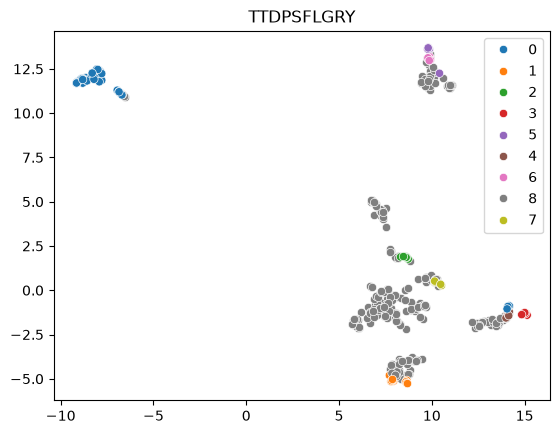

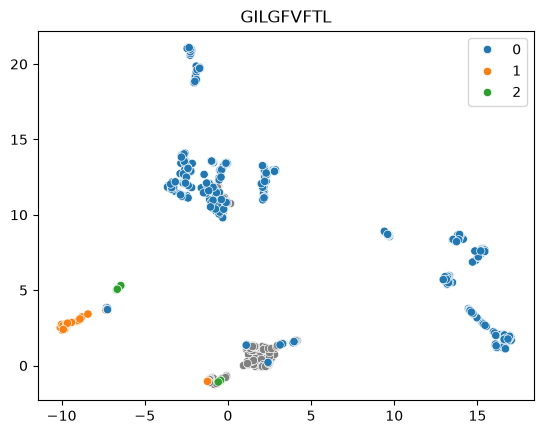

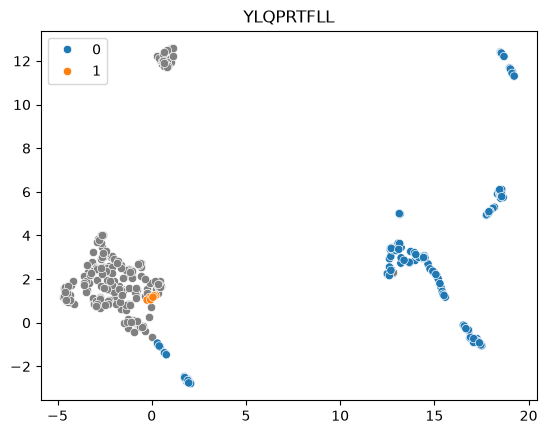

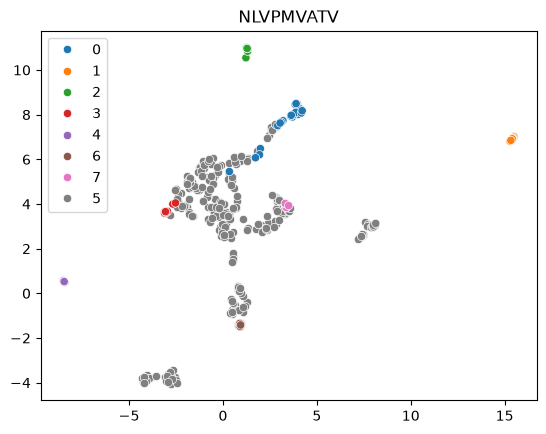

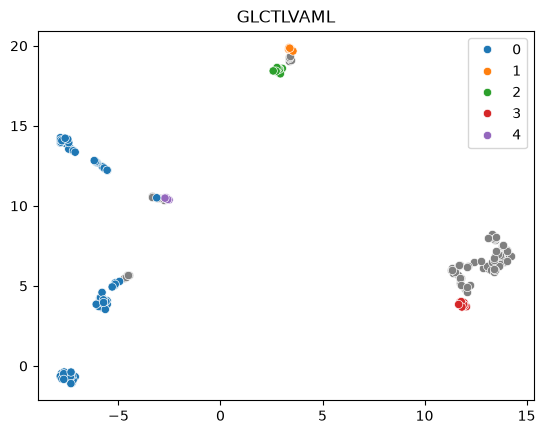

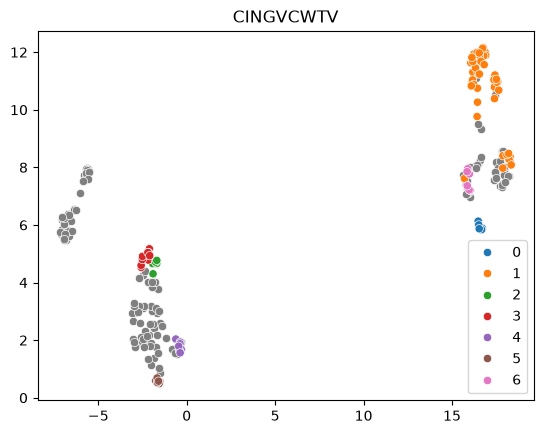

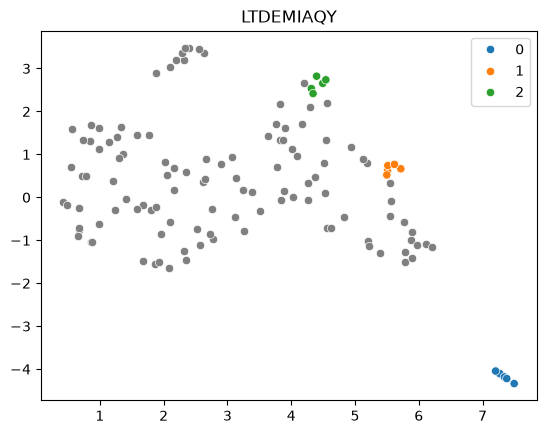

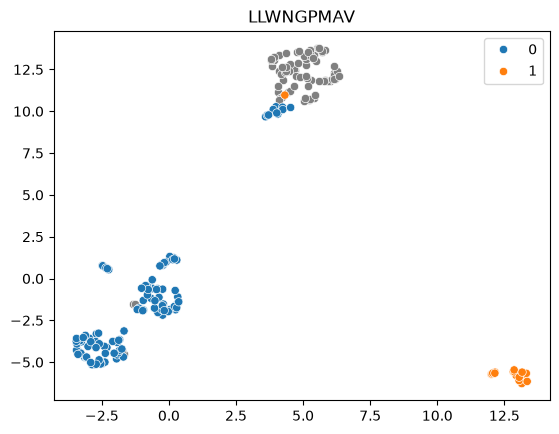

In [6]:
predictions['combined'] = 0

for peptide in sequences['peptide'].unique():
    mask = (sequences['peptide'] == peptide).to_numpy()
    peptide_distances = distance_matrices_combined[np.ix_(mask, mask)]

    peptide_umap = UMAP(random_state=123, n_jobs=1).fit_transform(peptide_distances)
    clusters = DBSCAN(eps=15, metric='precomputed').fit_predict(peptide_distances)
    clusters = clusters.astype(str)
    clusters = np.array([cluster if cluster != '-1' else 'None' for cluster in clusters])

    cluster_mask = clusters != 'None'

    predictions.loc[mask, 'combined'] += cluster_mask.astype(int)

    fig, ax = plt.subplots(1, 1)

    ax.set_title(peptide)

    sns.scatterplot(x=peptide_umap[~cluster_mask, 0], y=peptide_umap[~cluster_mask, 1], color='grey', ax=ax)
    sns.scatterplot(x=peptide_umap[cluster_mask, 0], y=peptide_umap[cluster_mask, 1], hue=clusters[cluster_mask], ax=ax)

    plt.show()

In [7]:
distance_matrices_cdr3 = distance_matrices['cdr3_alpha'] + distance_matrices['cdr3_beta']

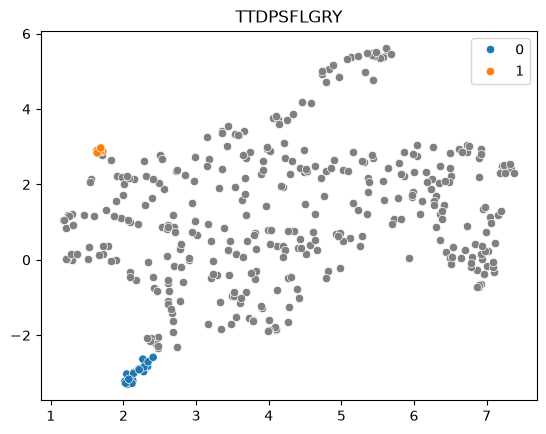

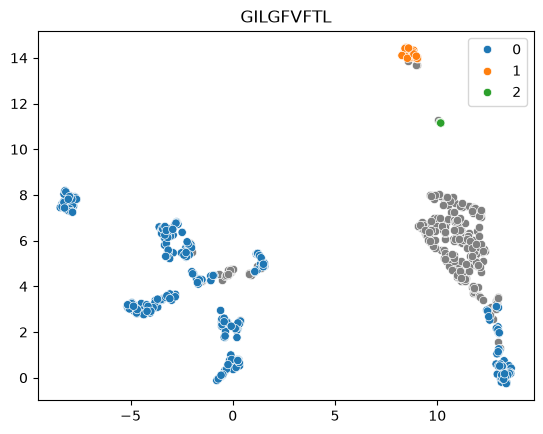

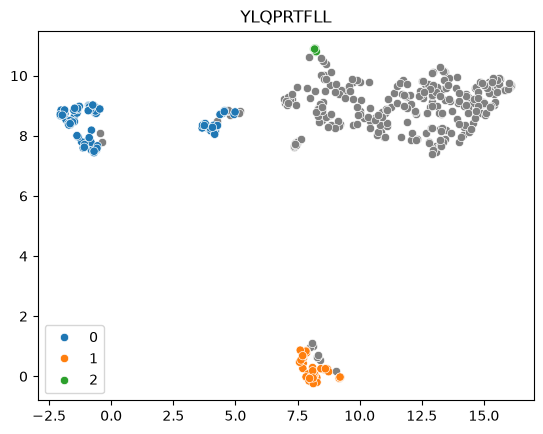

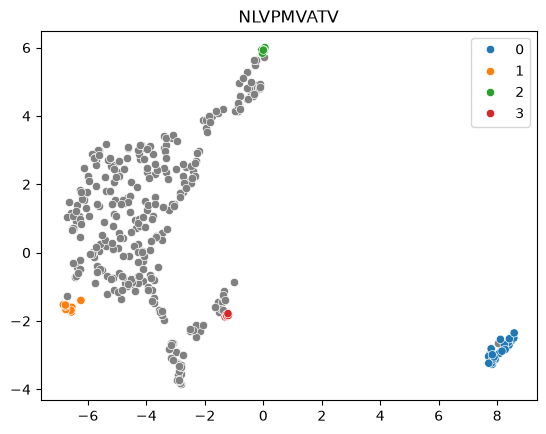

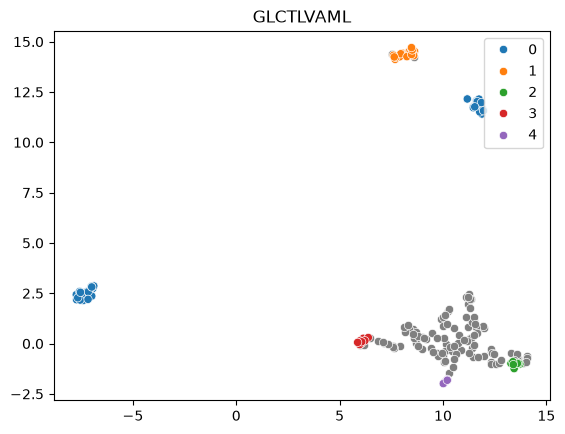

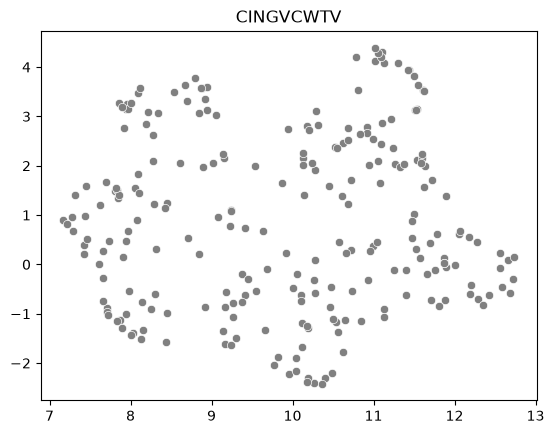

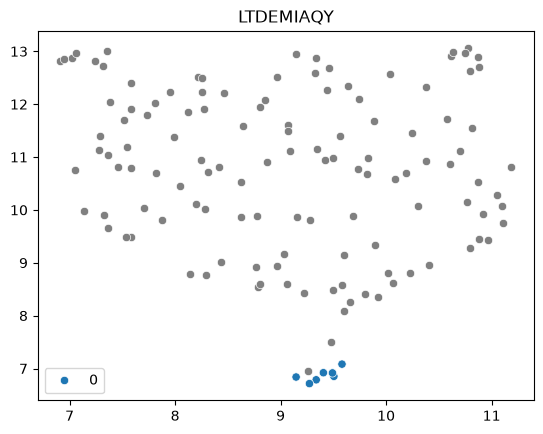

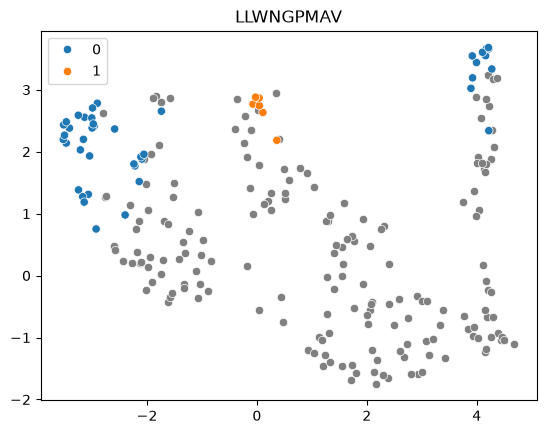

In [8]:
predictions['cdr3'] = 0

for peptide in sequences['peptide'].unique():
    mask = (sequences['peptide'] == peptide).to_numpy()
    peptide_distances = distance_matrices_cdr3[np.ix_(mask, mask)]

    peptide_umap = UMAP(random_state=123, n_jobs=1).fit_transform(peptide_distances)
    clusters = DBSCAN(eps=5, metric='precomputed').fit_predict(peptide_distances)
    clusters = clusters.astype(str)
    clusters = np.array([cluster if cluster != '-1' else 'None' for cluster in clusters])

    cluster_mask = clusters != 'None'

    predictions.loc[mask, 'cdr3'] += cluster_mask.astype(int)

    fig, ax = plt.subplots(1, 1)

    ax.set_title(peptide)

    sns.scatterplot(x=peptide_umap[~cluster_mask, 0], y=peptide_umap[~cluster_mask, 1], color='grey', ax=ax)
    sns.scatterplot(x=peptide_umap[cluster_mask, 0], y=peptide_umap[cluster_mask, 1], hue=clusters[cluster_mask], ax=ax)

    plt.show()

In [9]:
(predictions.value_counts(['combined', 'cdr3'], normalize=True) * 100).reset_index()

,combined,cdr3,proportion
0,0,0,51.631259
1,1,1,27.845220
2,1,0,20.409712
3,0,1,0.113809


In [10]:
public_labels = pd.read_csv('../data/external/ttd_gil_ylq_nlv_glc_01-10-2026_TCRvdb.csv', index_col='tcr_id')

In [11]:
predictions_public = predictions.merge(
    public_labels.query('ambiguous == 0'), how='inner', left_index=True, right_index=True
)

In [12]:
print('Overall ROC-AUC for combined method:', roc_auc_score(predictions_public['pos'], predictions_public['combined']))
print('Overall ROC-AUC for CDR3-only method:', roc_auc_score(predictions_public['pos'], predictions_public['cdr3']))

Overall ROC-AUC for combined method: 0.7994177840508115
Overall ROC-AUC for CDR3-only method: 0.7355907853614275


In [13]:
per_peptide_performance = (
    predictions_public.groupby('epitope_aa')
    .apply(lambda group: roc_auc_score(group['pos'], group['combined']), include_groups=False)
    .sort_values(ascending=False)
)

print(per_peptide_performance, end='\n\n')
print('Macro-averaged ROC-AUC for combined method:', per_peptide_performance.mean())

epitope_aa
YLQPRTFLL     0.895428
GILGFVFTL     0.780360
TTDPSFLGRY    0.735602
NLVPMVATV     0.699504
GLCTLVAML     0.666721
dtype: float64

Macro-averaged ROC-AUC for combined method: 0.7555229365384869


In [14]:
(
    predictions[['combined']]
    .rename({'combined': 'prediction'}, axis='columns')
    .reset_index()
    .to_csv('../data/processed/baseline_sequence_clusters.csv', index=False)
)